In [5]:
#!/usr/bin/python

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

url = 'https://raw.githubusercontent.com/coledd/keras-example/master/moon_data.csv'

# Load the training data, format: x, y, label

dataset = pd.read_csv(url)

In [6]:
dataset.head()

,0.743461,0.464656,0
0,1.657557,-0.632032,1
1,-0.158789,0.255845,1
2,-1.088752,-0.396943,0
3,1.768052,-0.254432,1
4,1.954165,-0.128506,1


In [7]:
dataset.columns

Index(['0.743461', ' 0.464656', ' 0'], dtype='object')

In [8]:
dataset.columns = ['X1', 'X2', 'Y']

class_names = ['clase_1', 'clase_2']
dataset.head()

,X1,X2,Y
0,1.657557,-0.632032,1
1,-0.158789,0.255845,1
2,-1.088752,-0.396943,0
3,1.768052,-0.254432,1
4,1.954165,-0.128506,1


In [9]:
dataset.shape

(199, 3)

In [10]:
data = dataset[['X1', 'X2']].values
labels = dataset['Y'].values

print(data.shape)
print(labels.shape)

(199, 2)
(199,)


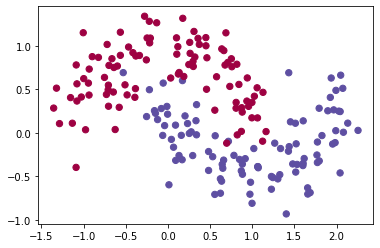

In [11]:
plt.scatter(data[:,0], data[:,1], s=40, c=labels, cmap=plt.cm.Spectral)
plt.show()

In [12]:
# Split the data into training and test data
data_train, data_test, labels_train, labels_test = train_test_split(data, labels, test_size=0.10)

In [16]:
data_train.shape

(179, 2)

In [13]:
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout

# Build the model
model = Sequential()
model.add(Dense(50, activation='tanh' , input_shape=(2,), name = "Capa_de_Entrada"))
# model.add(Dense(5, activation='tanh'   , name = "Capa_de_Oculta"))
model.add(Dense(1, activation='sigmoid', name = "Capa_de_Salida"))

In [14]:
# Configure a model for mean-squared error regression.
model.compile(loss='binary_crossentropy', optimizer='adam')

In [15]:
# checkpointer = keras.callbacks.ModelCheckpoint(filepath="weights.h5", verbose=1, save_best_only=True)
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Capa_de_Entrada (Dense)     (None, 50)                150       
                                                                 
 Capa_de_Salida (Dense)      (None, 1)                 51        
                                                                 
Total params: 201
Trainable params: 201
Non-trainable params: 0
_________________________________________________________________


Epoch 1/300
6/6 [==============================] - 0s 18ms/step - loss: 0.2013 - val_loss: 0.2031
Epoch 2/300
6/6 [==============================] - 0s 9ms/step - loss: 0.2013 - val_loss: 0.2032
Epoch 3/300
6/6 [==============================] - 0s 8ms/step - loss: 0.2013 - val_loss: 0.2040
Epoch 4/300
6/6 [==============================] - 0s 8ms/step - loss: 0.2012 - val_loss: 0.2056
Epoch 5/300
6/6 [==============================] - 0s 9ms/step - loss: 0.2006 - val_loss: 0.2083
Epoch 6/300
6/6 [==============================] - 0s 8ms/step - loss: 0.2002 - val_loss: 0.2099
Epoch 7/300
6/6 [==============================] - 0s 9ms/step - loss: 0.2000 - val_loss: 0.2114
Epoch 8/300
6/6 [==============================] - 0s 9ms/step - loss: 0.1997 - val_loss: 0.2141
Epoch 9/300
6/6 [==============================] - 0s 9ms/step - loss: 0.1997 - val_loss: 0.2193
Epoch 10/300
6/6 [==============================] - 0s 10ms/step - loss: 0.1994 - val_loss: 0.2224
Epoch 11/300
6/6 [=========

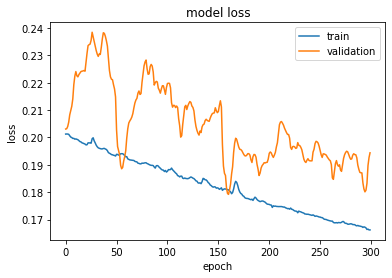

In [ ]:
# Train the model
history = model.fit(data_train, labels_train, epochs=300, verbose=1, validation_split=0.1)
model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [ ]:
# Evaluar
print(model.evaluate(data, labels))
print(model.metrics_names)

7/7 [==============================] - 0s 2ms/step - loss: 0.3822
0.3822405934333801
['loss']


In [ ]:
def plot_image(i, predictions_array, true_label, data, data_test):
  predictions_array, true_label, data, data_test = predictions_array, true_label[i], data, data_test[i] 
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.scatter(data[:,0], data[:,1], s=40, c=labels, cmap=plt.cm.Spectral)
  plt.scatter(data_test[0],data_test[1],s=[100],color='black', marker='*') 

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'red'
  else:
    color = 'blue'

  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  predictions_array, true_label = predictions_array, true_label[i]
  plt.grid(False)
  plt.xticks(range(2))
  plt.yticks([])
  thisplot = plt.bar(['predicho = '+np.array_str(predictions_array), 'real = '+str(true_label)], [predictions_array, true_label], color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('#2f3e3f')
  thisplot[true_label].set_color('#2f3e3f')

/usr/local/lib/python3.7/dist-packages/numpy/lib/stride_tricks.py:256: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  args = [np.array(_m, copy=False, subok=subok) for _m in args]


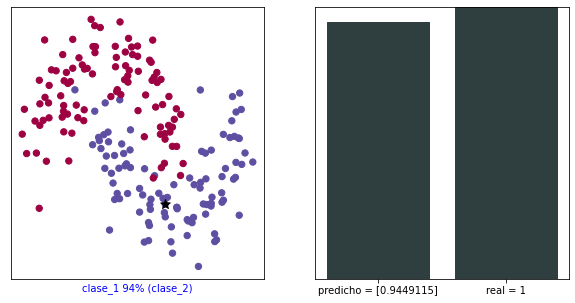

In [ ]:
predictions = model.predict(data_test)

i = 10
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plot_image(i, predictions[i], labels_test, data, data_test)
plt.subplot(1,2,2)
plot_value_array(i, predictions[i],  labels_test)
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report  

predict_label = predictions.reshape(-1).round()

print('Cantidad de predicciones = {} \n'.format(predict_label.shape))

cf_matrix = confusion_matrix(labels_test, predict_label)
print(cf_matrix)

Cantidad de predicciones = (20,) 

[[ 6  0]
 [ 2 12]]


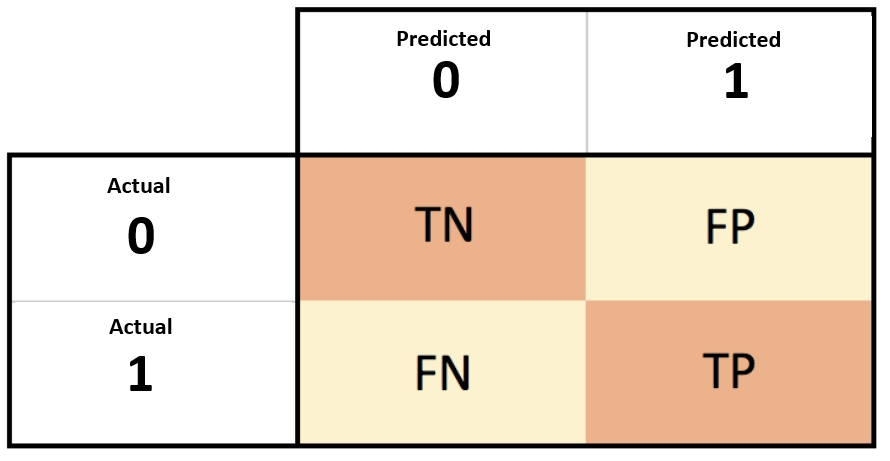

In [ ]:
import seaborn as sns
sns.heatmap(cf_matrix, annot=True)

In [ ]:
sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True, 
            fmt='.2%', cmap='Blues')

In [ ]:
report = classification_report(labels_test, predict_label)  
print(report)

**Referencias**

*   https://enmilocalfunciona.io/deep-learning-basico-con-keras-parte-1/
*   https://github.com/coledd/keras-example
*   https://medium.com/@dtuk81/confusion-matrix-visualization-fc31e3f30fea

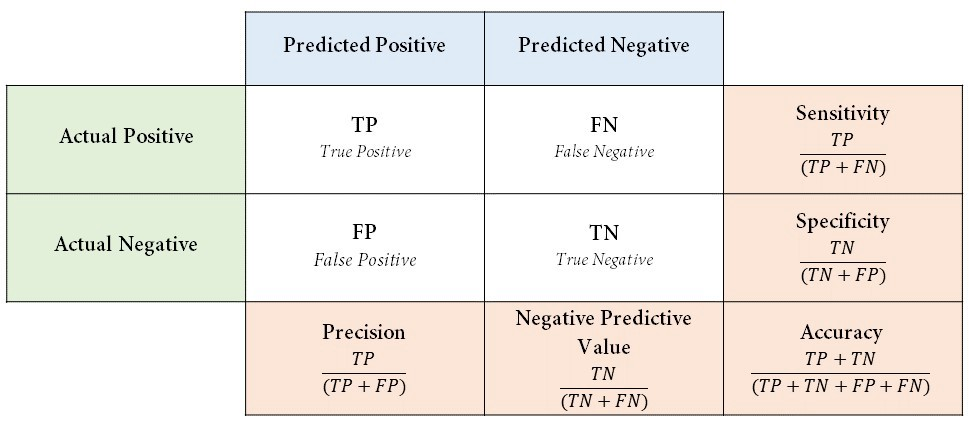